# 🎓 Student Performance Analysis

## Project Overview

This project analyzes 2,000 simulated student records to understand
academic performance and identify factors associated with student
outcomes.

The analysis focuses on academic scores, attendance, study hours,
test preparation, gender, parental education, and pass/fail
performance.

## Objectives

- Analyze overall student academic performance
- Calculate pass and fail rates
- Compare performance across subjects
- Analyze the relationship between attendance and scores
- Analyze study hours and academic performance
- Evaluate the impact of test preparation
- Compare performance across gender groups
- Analyze parental education and student performance
- Identify correlations between academic variables
- Generate actionable educational insights and recommendations

## Dataset

The dataset contains 2,000 simulated student records created for
analytical practice.

The dataset includes:

- Student demographics
- Parental education
- Lunch type
- Test preparation
- Attendance
- Study hours
- Math scores
- Reading scores
- Writing scores
- Overall scores
- Pass/fail result

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [30]:
np.random.seed(42)

n = 2000

df = pd.DataFrame({
    "Student_ID": range(1, n + 1),

    "Gender": np.random.choice(
        ["Female", "Male"],
        size=n
    ),

    "Parental_Education": np.random.choice(
        [
            "High School",
            "Some College",
            "Associate Degree",
            "Bachelor's Degree",
            "Master's Degree"
        ],
        size=n
    ),

    "Lunch": np.random.choice(
        ["Standard", "Free/Reduced"],
        size=n,
        p=[0.65, 0.35]
    ),

    "Test_Preparation": np.random.choice(
        ["Completed", "None"],
        size=n,
        p=[0.35, 0.65]
    ),

    "Attendance": np.random.randint(
        60, 101,
        size=n
    ),

    "Study_Hours": np.random.randint(
        1, 11,
        size=n
    )
})

df.head()

,Student_ID,Gender,Parental_Education,Lunch,Test_Preparation,Attendance,Study_Hours
0,1,Female,Bachelor's Degree,Free/Reduced,Completed,81,10
1,2,Male,Associate Degree,Standard,Completed,86,9
2,3,Female,Master's Degree,Standard,Completed,72,4
3,4,Female,High School,Standard,Completed,92,3
4,5,Female,Master's Degree,Standard,None,64,2


In [31]:
df["Math_Score"] = (
    20
    + df["Attendance"] * 0.25
    + df["Study_Hours"] * 1.2
    + np.where(
        df["Test_Preparation"] == "Completed",
        5,
        0
    )
    + np.random.normal(0, 10, n)
)

df["Reading_Score"] = (
    25
    + df["Attendance"] * 0.23
    + df["Study_Hours"] * 1.0
    + np.where(
        df["Test_Preparation"] == "Completed",
        5,
        0
    )
    + np.random.normal(0, 10, n)
)

df["Writing_Score"] = (
    23
    + df["Attendance"] * 0.24
    + df["Study_Hours"] * 1.1
    + np.where(
        df["Test_Preparation"] == "Completed",
        6,
        0
    )
    + np.random.normal(0, 10, n)
)

# Keep scores between 0 and 100
for column in [
    "Math_Score",
    "Reading_Score",
    "Writing_Score"
]:
    df[column] = (
        df[column]
        .clip(0, 100)
        .round(2)
    )

df.head()

,Student_ID,Gender,Parental_Education,Lunch,Test_Preparation,Attendance,Study_Hours,Math_Score,Reading_Score,Writing_Score
0,1,Female,Bachelor's Degree,Free/Reduced,Completed,81,10,64.78,59.94,63.50
1,2,Male,Associate Degree,Standard,Completed,86,9,58.64,53.37,54.54
2,3,Female,Master's Degree,Standard,Completed,72,4,53.57,53.38,60.08
3,4,Female,High School,Standard,Completed,92,3,39.31,51.20,37.15
4,5,Female,Master's Degree,Standard,None,64,2,43.89,28.31,46.54


In [32]:
df["Overall_Score"] = (
    df["Math_Score"]
    + df["Reading_Score"]
    + df["Writing_Score"]
) / 3

df["Overall_Score"] = df["Overall_Score"].round(2)

df["Result"] = np.where(
    df["Overall_Score"] >= 50,
    "Pass",
    "Fail"
)

df[[
    "Student_ID",
    "Math_Score",
    "Reading_Score",
    "Writing_Score",
    "Overall_Score",
    "Result"
]].head()

,Student_ID,Math_Score,Reading_Score,Writing_Score,Overall_Score,Result
0,1,64.78,59.94,63.50,62.74,Pass
1,2,58.64,53.37,54.54,55.52,Pass
2,3,53.57,53.38,60.08,55.68,Pass
3,4,39.31,51.20,37.15,42.55,Fail
4,5,43.89,28.31,46.54,39.58,Fail


In [33]:
result_counts = df["Result"].value_counts()

print(result_counts)

print("\nPercentage:")
print(
    df["Result"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Result
Fail    1026
Pass     974
Name: count, dtype: int64

Percentage:
Result
Fail    51.3
Pass    48.7
Name: proportion, dtype: float64


In [34]:
import os

os.makedirs("../data", exist_ok=True)

df.to_csv(
    "../data/student_performance.csv",
    index=False
)

print("Student dataset saved successfully.")

Student dataset saved successfully.


In [35]:
print(
    os.path.exists(
        "../data/student_performance.csv"
    )
)

True


In [36]:
df = pd.read_csv(
    "../data/student_performance.csv"
)

df.head()

,Student_ID,Gender,Parental_Education,Lunch,Test_Preparation,Attendance,Study_Hours,Math_Score,Reading_Score,Writing_Score,Overall_Score,Result
0,1,Female,Bachelor's Degree,Free/Reduced,Completed,81,10,64.78,59.94,63.50,62.74,Pass
1,2,Male,Associate Degree,Standard,Completed,86,9,58.64,53.37,54.54,55.52,Pass
2,3,Female,Master's Degree,Standard,Completed,72,4,53.57,53.38,60.08,55.68,Pass
3,4,Female,High School,Standard,Completed,92,3,39.31,51.20,37.15,42.55,Fail
4,5,Female,Master's Degree,Standard,NaN,64,2,43.89,28.31,46.54,39.58,Fail


## 3. Data Exploration and Quality Checks

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student_ID          2000 non-null   int64  
 1   Gender              2000 non-null   str    
 2   Parental_Education  2000 non-null   str    
 3   Lunch               2000 non-null   str    
 4   Test_Preparation    724 non-null    str    
 5   Attendance          2000 non-null   int64  
 6   Study_Hours         2000 non-null   int64  
 7   Math_Score          2000 non-null   float64
 8   Reading_Score       2000 non-null   float64
 9   Writing_Score       2000 non-null   float64
 10  Overall_Score       2000 non-null   float64
 11  Result              2000 non-null   str    
dtypes: float64(4), int64(3), str(5)
memory usage: 187.6 KB


In [38]:
df.isnull().sum()

Student_ID               0
Gender                   0
Parental_Education       0
Lunch                    0
Test_Preparation      1276
Attendance               0
Study_Hours              0
Math_Score               0
Reading_Score            0
Writing_Score            0
Overall_Score            0
Result                   0
dtype: int64

In [39]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [40]:
print("Total students:", len(df))
print("Unique Student IDs:", df["Student_ID"].nunique())

Total students: 2000
Unique Student IDs: 2000


In [41]:
for column in [
    "Math_Score",
    "Reading_Score",
    "Writing_Score",
    "Overall_Score"
]:
    invalid = (
        (df[column] < 0) |
        (df[column] > 100)
    ).sum()

    print(f"{column}: {invalid} invalid values")

Math_Score: 0 invalid values
Reading_Score: 0 invalid values
Writing_Score: 0 invalid values
Overall_Score: 0 invalid values


In [42]:
df[
    [
        "Attendance",
        "Study_Hours",
        "Math_Score",
        "Reading_Score",
        "Writing_Score",
        "Overall_Score"
    ]
].describe()

,Attendance,Study_Hours,Math_Score,Reading_Score,Writing_Score,Overall_Score
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,79.540500,5.573000,48.461630,50.482635,50.586000,49.843430
std,11.698923,2.846528,11.274014,10.775479,11.308816,7.445061
min,60.000000,1.000000,12.430000,6.640000,2.630000,25.480000
25%,70.000000,3.000000,40.952500,43.322500,43.135000,44.797500
50%,79.000000,6.000000,48.570000,50.405000,50.730000,49.745000
75%,90.000000,8.000000,55.932500,57.552500,58.052500,54.685000
max,100.000000,10.000000,85.980000,88.870000,85.720000,78.110000


## 4. Key Performance Indicators

In [43]:
average_math = df["Math_Score"].mean()
average_reading = df["Reading_Score"].mean()
average_writing = df["Writing_Score"].mean()
average_overall = df["Overall_Score"].mean()

pass_rate = (df["Result"] == "Pass").mean() * 100
fail_rate = (df["Result"] == "Fail").mean() * 100

print(f"Average Math Score: {average_math:.2f}")
print(f"Average Reading Score: {average_reading:.2f}")
print(f"Average Writing Score: {average_writing:.2f}")
print(f"Average Overall Score: {average_overall:.2f}")
print(f"Pass Rate: {pass_rate:.2f}%")
print(f"Fail Rate: {fail_rate:.2f}%")

Average Math Score: 48.46
Average Reading Score: 50.48
Average Writing Score: 50.59
Average Overall Score: 49.84
Pass Rate: 48.70%
Fail Rate: 51.30%


In [44]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Average Math Score",
        "Average Reading Score",
        "Average Writing Score",
        "Average Overall Score",
        "Pass Rate",
        "Fail Rate"
    ],
    "Value": [
        average_math,
        average_reading,
        average_writing,
        average_overall,
        pass_rate,
        fail_rate
    ]
})

kpi_summary

,KPI,Value
0,Average Math Score,48.461630
1,Average Reading Score,50.482635
2,Average Writing Score,50.586000
3,Average Overall Score,49.843430
4,Pass Rate,48.700000
5,Fail Rate,51.300000


## 5. Subject Performance Analysis

In [45]:
subject_means = pd.Series({
    "Math": df["Math_Score"].mean(),
    "Reading": df["Reading_Score"].mean(),
    "Writing": df["Writing_Score"].mean()
})

subject_means

Math       48.461630
Reading    50.482635
Writing    50.586000
dtype: float64

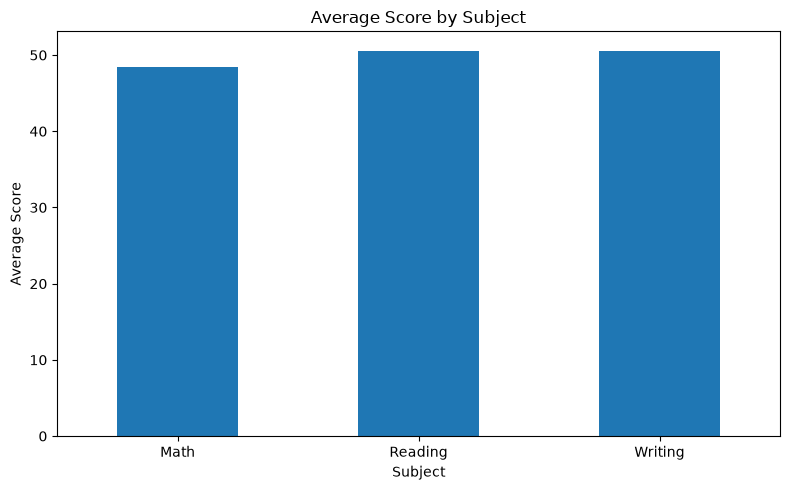

In [46]:
import os

os.makedirs("../visualizations", exist_ok=True)

plt.figure(figsize=(8, 5))

subject_means.plot(kind="bar")

plt.title("Average Score by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/average_subject_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
print(
    os.path.exists(
        "../visualizations/average_subject_scores.png"
    )
)

True


## 6. Pass and Fail Analysis

In [48]:
result_counts = df["Result"].value_counts()

result_counts

Result
Fail    1026
Pass     974
Name: count, dtype: int64

In [49]:
result_percentages = (
    df["Result"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

result_percentages

Result
Fail    51.3
Pass    48.7
Name: proportion, dtype: float64

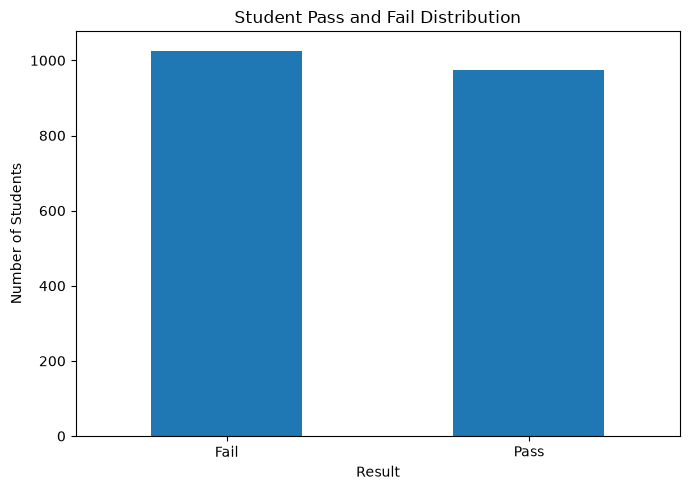

In [50]:
plt.figure(figsize=(7, 5))

result_counts.plot(kind="bar")

plt.title("Student Pass and Fail Distribution")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/pass_fail_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
print(
    os.path.exists(
        "../visualizations/pass_fail_distribution.png"
    )
)

True


## 7. Attendance and Academic Performance

In [53]:
attendance_groups = pd.cut(
    df["Attendance"],
    bins=[59, 70, 80, 90, 100],
    labels=[
        "60-70%",
        "71-80%",
        "81-90%",
        "91-100%"
    ]
)

attendance_performance = df.groupby(
    attendance_groups,
    observed=False
)["Overall_Score"].mean()

attendance_performance

Attendance
60-70%     46.451337
71-80%     48.838911
81-90%     50.915209
91-100%    53.924731
Name: Overall_Score, dtype: float64

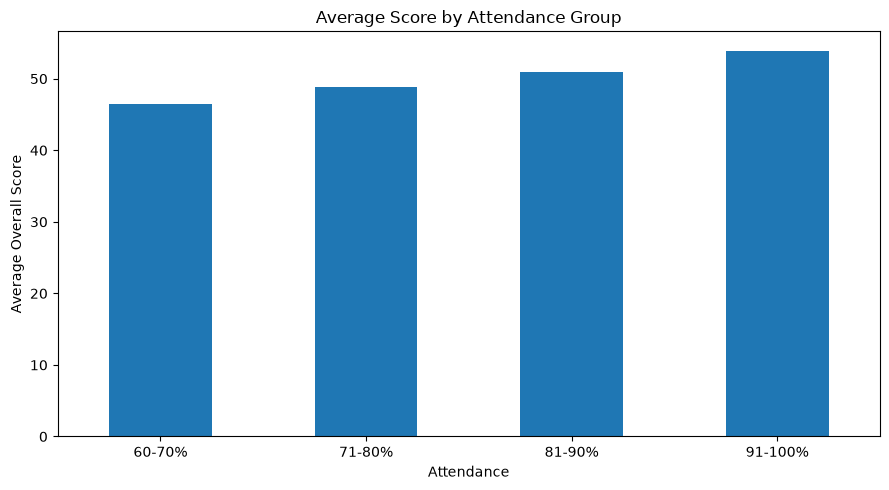

In [54]:
plt.figure(figsize=(9, 5))

attendance_performance.plot(kind="bar")

plt.title("Average Score by Attendance Group")
plt.xlabel("Attendance")
plt.ylabel("Average Overall Score")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/attendance_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [55]:
print(
    os.path.exists(
        "../visualizations/attendance_performance.png"
    )
)

True


## 8. Study Hours and Academic Performance

In [56]:
study_performance = (
    df.groupby("Study_Hours")["Overall_Score"]
    .mean()
)

study_performance

Study_Hours
1     45.714404
2     45.079191
3     47.239029
4     47.031568
5     49.274569
6     51.199245
7     52.013474
8     52.879860
9     52.686243
10    54.211810
Name: Overall_Score, dtype: float64

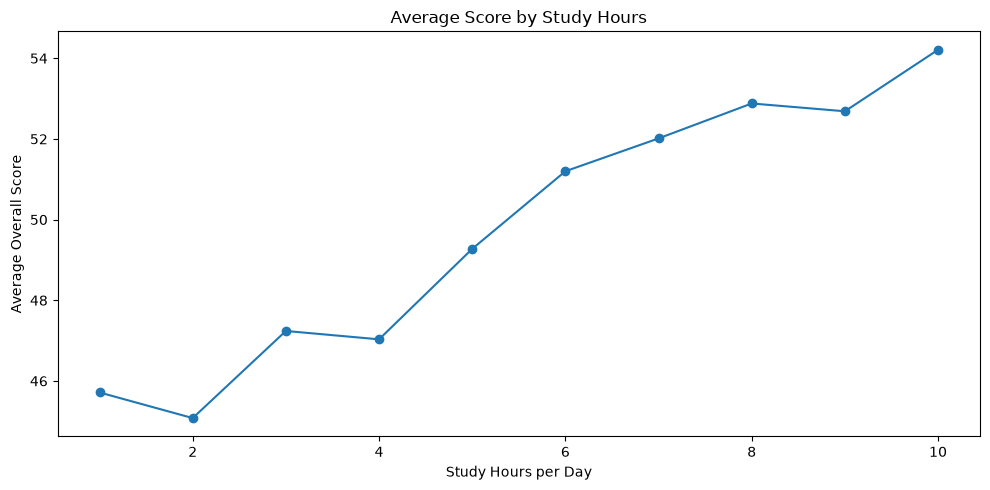

In [57]:
plt.figure(figsize=(10, 5))

study_performance.plot(
    kind="line",
    marker="o"
)

plt.title("Average Score by Study Hours")
plt.xlabel("Study Hours per Day")
plt.ylabel("Average Overall Score")

plt.tight_layout()

plt.savefig(
    "../visualizations/study_hours_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
print(
    os.path.exists(
        "../visualizations/study_hours_performance.png"
    )
)

True


In [64]:
test_prep_analysis = df.groupby(
    "Test_Preparation"
).agg(
    Average_Score=("Overall_Score", "mean"),
    Pass_Rate=("Result", lambda x: (x == "Pass").mean() * 100),
    Students=("Student_ID", "count")
)

test_prep_analysis

,Average_Score,Pass_Rate,Students
Test_Preparation,,,
Completed,52.991146,64.502762,724
None,48.057422,39.733542,1276


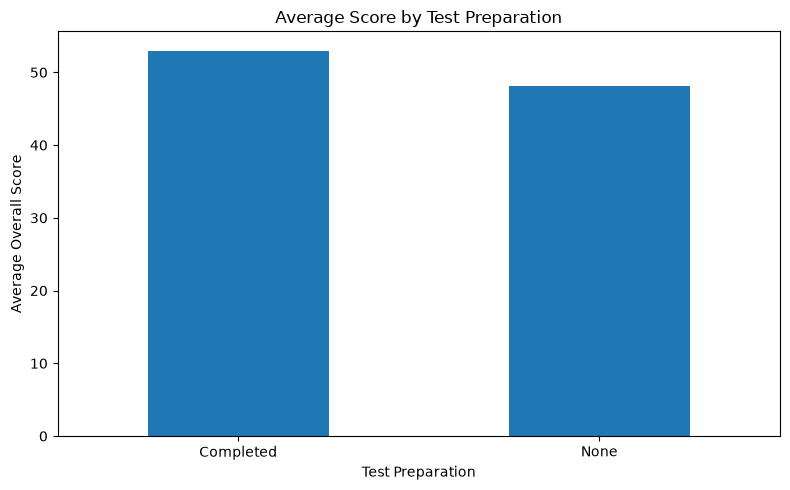

In [67]:
plt.figure(figsize=(8, 5))

test_prep_analysis["Average_Score"].plot(kind="bar")

plt.title("Average Score by Test Preparation")
plt.xlabel("Test Preparation")
plt.ylabel("Average Overall Score")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/test_preparation_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [68]:
print(os.path.exists("../visualizations/test_preparation_scores.png"))

True


In [69]:
gender_analysis = df.groupby("Gender").agg(
    Average_Score=("Overall_Score", "mean"),
    Pass_Rate=("Result", lambda x: (x == "Pass").mean() * 100),
    Students=("Student_ID", "count")
)

gender_analysis

,Average_Score,Pass_Rate,Students
Gender,,,
Female,49.765689,49.212598,1016
Male,49.923699,48.170732,984


In [70]:
parent_education = df.groupby(
    "Parental_Education"
)["Overall_Score"].mean().sort_values(ascending=False)

parent_education

Parental_Education
Associate Degree     50.387728
Bachelor's Degree    50.032512
Master's Degree      49.723301
High School          49.587772
Some College         49.490311
Name: Overall_Score, dtype: float64

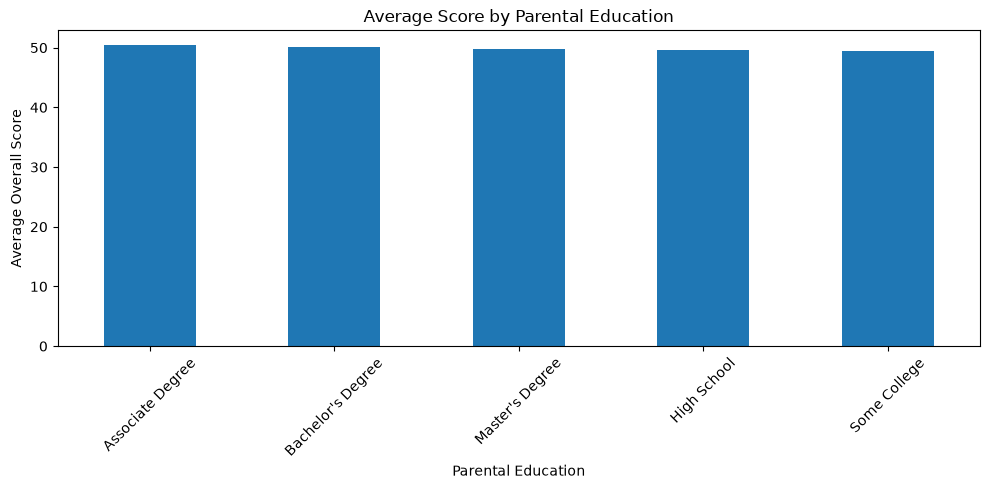

In [71]:
plt.figure(figsize=(10, 5))

parent_education.plot(kind="bar")

plt.title("Average Score by Parental Education")
plt.xlabel("Parental Education")
plt.ylabel("Average Overall Score")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../visualizations/parental_education_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [72]:
print(os.path.exists("../visualizations/parental_education_scores.png"))

True


In [73]:
correlation = df[[
    "Attendance",
    "Study_Hours",
    "Math_Score",
    "Reading_Score",
    "Writing_Score",
    "Overall_Score"
]].corr()

correlation

,Attendance,Study_Hours,Math_Score,Reading_Score,Writing_Score,Overall_Score
Attendance,1.000000,0.028746,0.233124,0.287072,0.234622,0.374967
Study_Hours,0.028746,1.000000,0.319911,0.216078,0.273266,0.404077
Math_Score,0.233124,0.319911,1.000000,0.153587,0.207202,0.683764
Reading_Score,0.287072,0.216078,0.153587,1.000000,0.154280,0.638091
Writing_Score,0.234622,0.273266,0.207202,0.154280,1.000000,0.685356
Overall_Score,0.374967,0.404077,0.683764,0.638091,0.685356,1.000000


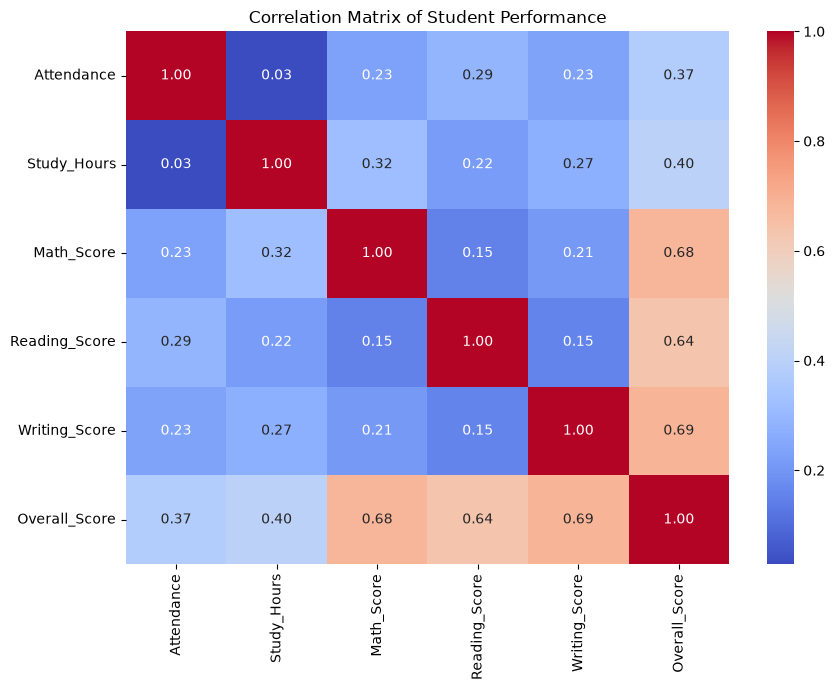

In [74]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Student Performance")
plt.tight_layout()

plt.savefig(
    "../visualizations/student_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [75]:
print(os.path.exists("../visualizations/student_correlation_matrix.png"))

True


In [76]:
mean_scores = df[
    ["Math_Score", "Reading_Score", "Writing_Score", "Overall_Score"]
].mean()

median_scores = df[
    ["Math_Score", "Reading_Score", "Writing_Score", "Overall_Score"]
].median()

print("MEAN SCORES")
print(mean_scores)

print("\nMEDIAN SCORES")
print(median_scores)

MEAN SCORES
Math_Score       48.461630
Reading_Score    50.482635
Writing_Score    50.586000
Overall_Score    49.843430
dtype: float64

MEDIAN SCORES
Math_Score       48.570
Reading_Score    50.405
Writing_Score    50.730
Overall_Score    49.745
dtype: float64


## 4. Educational Insights

### 1. Subject Performance
Writing had the highest average score at approximately 50.59, followed by Reading at 50.48. Math had the lowest average score at approximately 48.46, indicating that Math may require additional academic support.

### 2. Pass and Fail Performance
The overall pass rate was approximately 48.70%, while the fail rate was approximately 51.30%. This indicates that a significant proportion of students may benefit from additional academic support and early intervention.

### 3. Attendance and Academic Performance
Attendance showed a positive correlation of approximately 0.37 with Overall Score. Students with higher attendance generally showed better average academic performance.

### 4. Study Hours and Academic Performance
Study Hours had a positive correlation of approximately 0.40 with Overall Score. The analysis suggests that students spending more time studying tended to achieve higher scores.

### 5. Test Preparation
Students who completed test preparation had an average score of approximately 52.99 and a pass rate of 64.50%, compared with approximately 48.06 and 39.73% for students who did not complete test preparation.

### 6. Gender Comparison
The average scores were very similar between female and male students. Female students had an average score of approximately 49.77, while male students had approximately 49.92. Therefore, the dataset does not show a substantial difference in overall performance by gender.

### 7. Parental Education
Average scores varied only slightly across parental education groups. Associate Degree had the highest average score at approximately 50.39, while Some College had the lowest at approximately 49.49.

### 8. Subject Correlations
Math, Reading, and Writing scores showed strong positive relationships with Overall Score, with correlations of approximately 0.68, 0.64, and 0.69 respectively. Attendance and Study Hours showed moderate positive relationships with Overall Score.

## 5. Recommendations

### 1. Provide Additional Math Support
Math had the lowest average score among the three subjects. Schools can provide additional practice sessions, targeted exercises, and tutoring support for students struggling with Math.

### 2. Improve Attendance
Attendance showed a positive relationship with Overall Score. Schools should identify students with lower attendance and introduce early intervention programs to encourage regular attendance.

### 3. Encourage Structured Study Schedules
Study Hours had a positive relationship with Overall Score. Students should be encouraged to follow consistent study schedules and allocate sufficient time for academic preparation.

### 4. Promote Test Preparation Programs
Students who completed test preparation showed higher average scores and pass rates. Schools can encourage students to participate in structured test preparation and revision programs.

### 5. Early Academic Intervention
With approximately 51.30% of students failing in the dataset, educators should identify academically struggling students early and provide personalized support.

### 6. Focus on Individual Learning Needs
Gender and parental education showed relatively small differences in average performance. Academic support should therefore focus primarily on individual student needs, attendance, study habits, and subject-level performance rather than demographic characteristics.

### 7. Monitor Student Performance Regularly
Schools can use periodic performance analysis to track changes in scores, attendance, study habits, and pass rates and identify students who may require additional support.

## 6. Conclusion

This project analyzed the academic performance of 2,000 simulated students using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The analysis covered data quality validation, descriptive statistics, subject performance, pass/fail distribution, attendance, study hours, test preparation, gender, parental education, and correlation analysis.

The results showed that Math had the lowest average score, while Writing had the highest. Attendance and Study Hours showed positive relationships with Overall Score. Students who completed test preparation also demonstrated higher average scores and pass rates than students who did not.

The project demonstrates how data analysis and visualization can be used to identify performance patterns, understand factors associated with academic outcomes, and develop practical recommendations for improving student performance.

In [77]:
print("===== FINAL DATA QUALITY CHECK =====")

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nUnique Student IDs:")
print(df["Student_ID"].nunique())

print("\nStudent ID Count:")
print(len(df))

print("\nScore Range:")
for column in ["Math_Score", "Reading_Score", "Writing_Score", "Overall_Score"]:
    print(
        f"{column}: {df[column].min():.2f} - {df[column].max():.2f}"
    )

print("\nResult Distribution:")
print(df["Result"].value_counts())

print("\nTest Preparation Distribution:")
print(df["Test_Preparation"].value_counts())

print("\n===== QUALITY CHECK COMPLETE =====")

===== FINAL DATA QUALITY CHECK =====

Dataset Shape:
(2000, 12)

Missing Values:
0

Duplicate Rows:
0

Unique Student IDs:
2000

Student ID Count:
2000

Score Range:
Math_Score: 12.43 - 85.98
Reading_Score: 6.64 - 88.87
Writing_Score: 2.63 - 85.72
Overall_Score: 25.48 - 78.11

Result Distribution:
Result
Fail    1026
Pass     974
Name: count, dtype: int64

Test Preparation Distribution:
Test_Preparation
None         1276
Completed     724
Name: count, dtype: int64

===== QUALITY CHECK COMPLETE =====


---
## Project Status

**Status:** Completed

**Dataset:** 2,000 student records

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

**Analysis Areas:** Academic scores, pass/fail performance, attendance, study hours, test preparation, gender, parental education, descriptive statistics, and correlation analysis.

**Quality Checks:** Missing values, duplicates, Student ID uniqueness, score validation, and categorical value validation completed successfully.

In [79]:
import os

portfolio_data = r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\data"

os.makedirs(portfolio_data, exist_ok=True)

file_path = os.path.join(portfolio_data, "student_performance.csv")

df.to_csv(file_path, index=False)

print("Project 2 dataset saved to portfolio.")
print(file_path)
print(os.path.exists(file_path))

Project 2 dataset saved to portfolio.
C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\data\student_performance.csv
True


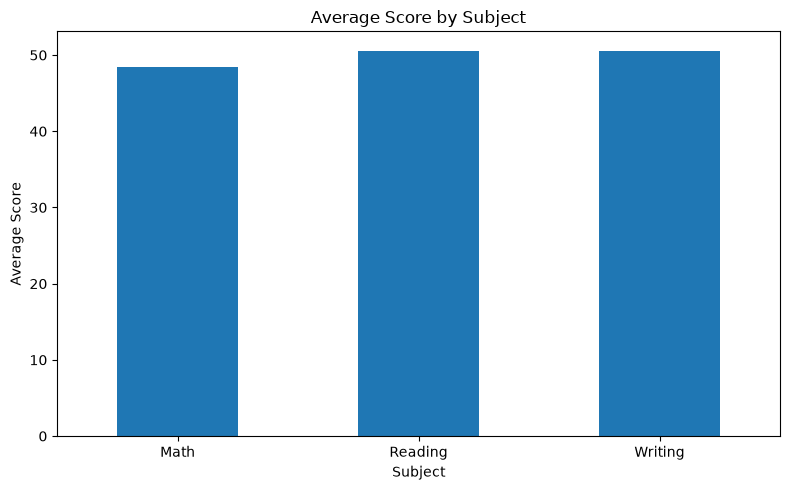

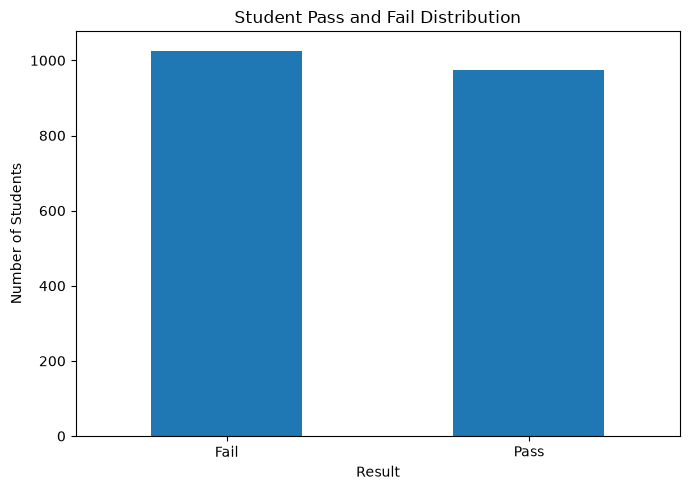

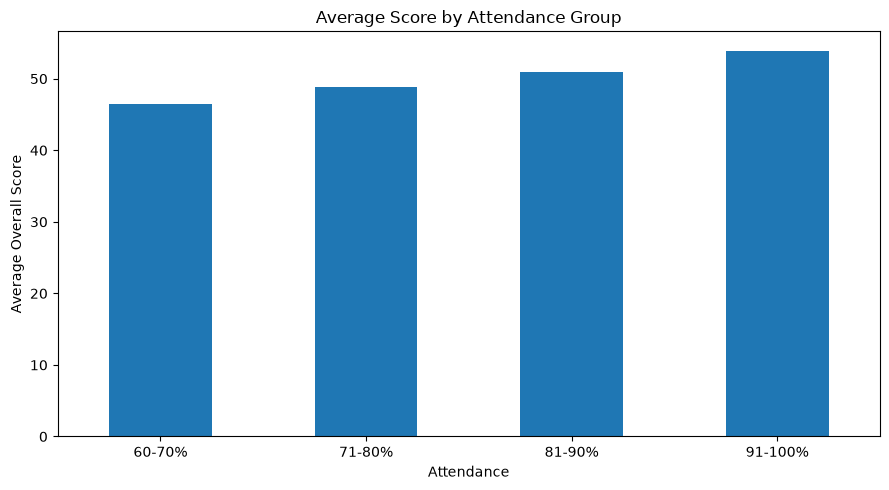

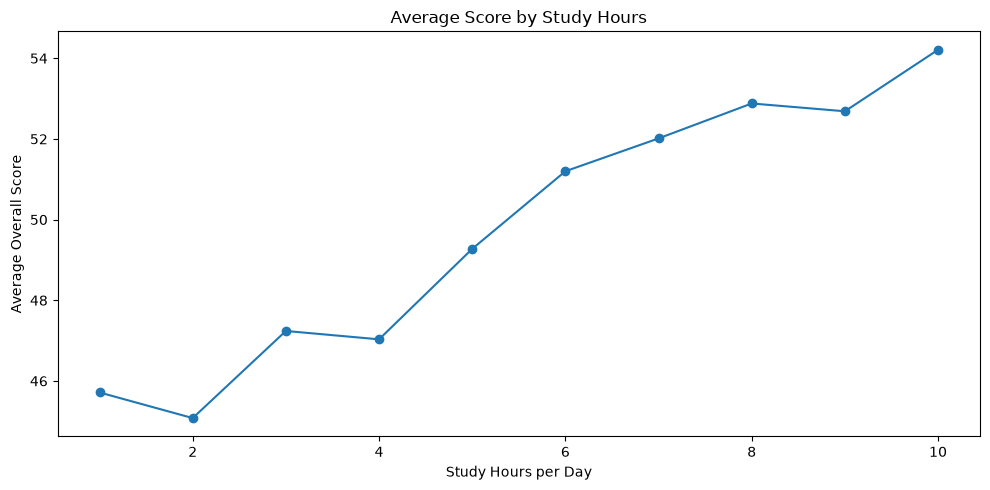

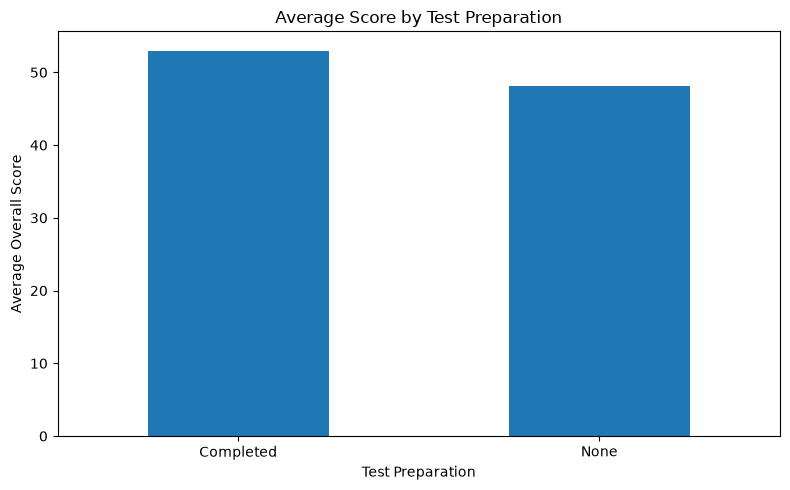

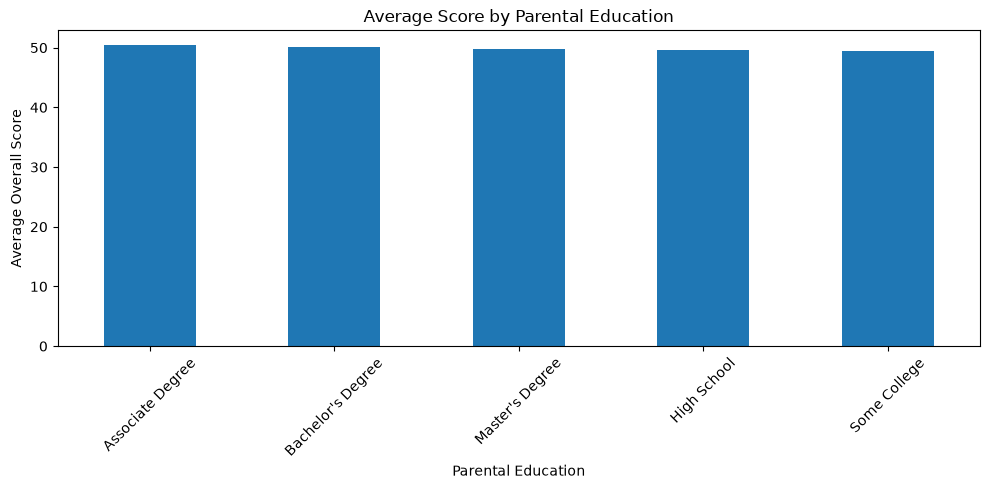

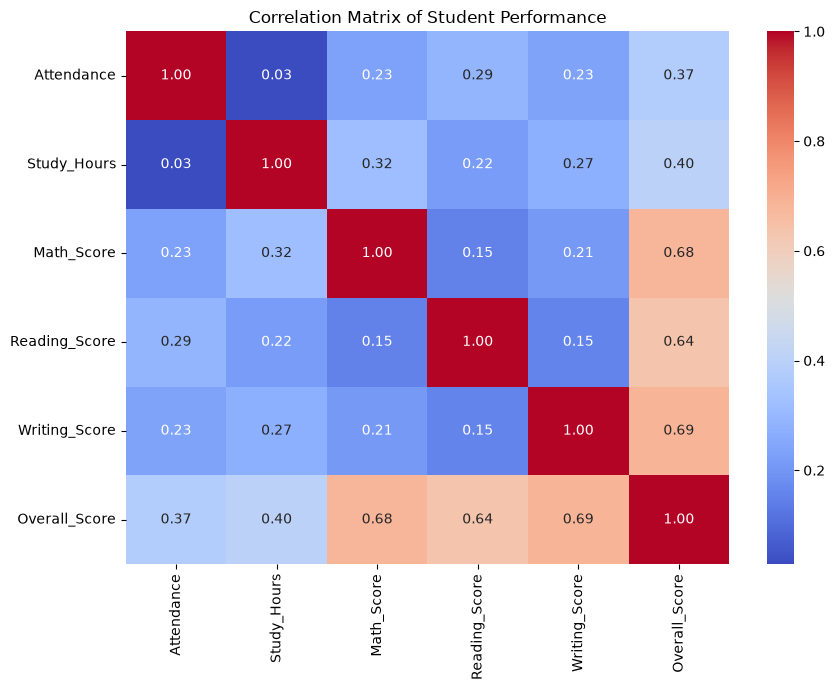

All Project 2 visualizations saved successfully.


In [80]:
import os
import matplotlib.pyplot as plt

portfolio_viz = r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations"
os.makedirs(portfolio_viz, exist_ok=True)

# 1. Average Subject Scores
plt.figure(figsize=(8, 5))
subject_means.plot(kind="bar")
plt.title("Average Score by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(portfolio_viz, "average_subject_scores.png"), dpi=300, bbox_inches="tight")
plt.show()

# 2. Pass/Fail Distribution
plt.figure(figsize=(7, 5))
result_counts.plot(kind="bar")
plt.title("Student Pass and Fail Distribution")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(portfolio_viz, "pass_fail_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

# 3. Attendance Performance
plt.figure(figsize=(9, 5))
attendance_performance.plot(kind="bar")
plt.title("Average Score by Attendance Group")
plt.xlabel("Attendance")
plt.ylabel("Average Overall Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(portfolio_viz, "attendance_performance.png"), dpi=300, bbox_inches="tight")
plt.show()

# 4. Study Hours Performance
plt.figure(figsize=(10, 5))
study_performance.plot(kind="line", marker="o")
plt.title("Average Score by Study Hours")
plt.xlabel("Study Hours per Day")
plt.ylabel("Average Overall Score")
plt.tight_layout()
plt.savefig(os.path.join(portfolio_viz, "study_hours_performance.png"), dpi=300, bbox_inches="tight")
plt.show()

# 5. Test Preparation
plt.figure(figsize=(8, 5))
test_prep_analysis["Average_Score"].plot(kind="bar")
plt.title("Average Score by Test Preparation")
plt.xlabel("Test Preparation")
plt.ylabel("Average Overall Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(portfolio_viz, "test_preparation_scores.png"), dpi=300, bbox_inches="tight")
plt.show()

# 6. Parental Education
plt.figure(figsize=(10, 5))
parent_education.plot(kind="bar")
plt.title("Average Score by Parental Education")
plt.xlabel("Parental Education")
plt.ylabel("Average Overall Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(portfolio_viz, "parental_education_scores.png"), dpi=300, bbox_inches="tight")
plt.show()

# 7. Correlation Matrix
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Student Performance")
plt.tight_layout()
plt.savefig(os.path.join(portfolio_viz, "student_correlation_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()

print("All Project 2 visualizations saved successfully.")